In [2]:
import sys
sys.path.append("../")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
from qitp.engine.unitary_approximation import UnitaryApproximation
from qitp.engine.propagation import QITEPropagation
from qitp.engine.cqite_run import run_qite
from qitp.engine.prepare_state import constraint_rotation, prepare_state, density_from_rotations, support_only
from qitp.simulation.backend import SimulatorBackend

In [4]:
from qitp.ansatz.pauli_basis import (
    PauliBasis
)
from qitp.ansatz.commutator_basis import (
    CommutatorBasis
)

In [65]:
depth=2
dt=1e-1/2
nqubits = 3

In [177]:
nsteps=70
target=0.4

energies=[]
fidelities=[]
errors=[]
magnetizations=[]

In [179]:
from qiskit.quantum_info import SparsePauliOp

J = 0.7

H = SparsePauliOp(
    [
        "ZZI",
        "ZIZ",
        "IZZ",
    ],
    coeffs=[J, J, J]
)

In [181]:
Mz = constraints = [
    SparsePauliOp(["XII"], coeffs=[1.0]),
    SparsePauliOp(["IXI"], coeffs=[1.0]),
    SparsePauliOp(["IIX"], coeffs=[1.0]),
]

Identity = SparsePauliOp(["III"],coeffs=[1.0])

In [183]:
H_eff = H + sum(Mz[1:], start=Mz[0])# + Identity

In [185]:
rotations = []

for constraint in Mz:

    rotations.append(
        constraint_rotation(
            constraint,
            target
        )
    )

In [187]:
rho = density_from_rotations(3, rotations, degree=2)

seeds = support_only(rho)

In [189]:
basis = CommutatorBasis.from_seed(hamiltonian=H_eff, seeds=seeds, depth=depth)

In [191]:
len(basis.paulis)

48

In [193]:
circuit = prepare_state(
    3,
    rotations
)

In [195]:
circuit = circuit.decompose()

In [197]:
approx = UnitaryApproximation(basis, trot=4)

backend = SimulatorBackend()

prop = QITEPropagation(
    H,
    backend,
    approx
)

prop.constraints = [
    Identity]
prop.constraints.extend(Mz)

In [198]:
from qiskit.quantum_info import Statevector

psi = Statevector.from_instruction(circuit)

In [201]:
results = run_qite(
    prop,
    circuit,
    H,
    Mz,
    dt,
    nsteps,
    state=psi #Remove for exponential advantage
)

In [202]:
energies = results["energies"]
magnetizations = results["magnetizations"] #[np.sum(m) for m in results["magnetizations"]]
circuit = results["circuit"]

In [203]:
print(np.round(energies[-1],3))

-0.7


In [204]:
print(np.round(magnetizations[-1],3))

[0.356 0.358 0.353]


In [205]:
#plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()

In [206]:
#plt.plot(magnetizations); plt.title("Magnetization"); plt.grid(); plt.show()

In [207]:
evals = np.linalg.eigvalsh(
    H.to_matrix()
)

print("Exact spectrum")

print(np.round(evals,2))

Exact spectrum
[-0.7 -0.7 -0.7 -0.7 -0.7 -0.7  2.1  2.1]


In [208]:
def compute_betas_dense(psi, Hm, constraints):

    m = len(constraints)

    gamma = np.zeros(m)
    Gmat = np.zeros((m,m))

    Hpsi = Hm @ psi

    for i, Bi in enumerate(constraints):

        Bipsi = Bi @ psi

        gamma[i] = -np.real(
            np.vdot(Hpsi, Bipsi)
        )

        for j, Bj in enumerate(constraints):

            Gmat[i,j] = np.real(
                np.vdot(
                    Bipsi,
                    Bj @ psi
                )
            )

    return np.linalg.pinv(Gmat) @ gamma

In [209]:
Hm = H.to_matrix()

In [210]:
C = []

for i in range(nqubits):

    p = ["I"] * nqubits
    p[i] = "X"

    C.append(
        SparsePauliOp(
            ["".join(p)],
            coeffs=[1.0]
        ).to_matrix()
    )

I = np.eye(Hm.shape[0])

constraints_mat = [I]
constraints_mat.extend(C)

In [211]:
from scipy.linalg import expm

def cite_step(
    psi,
    Hm,
    constraints_mat,
    dt,
    nsub=100
):

    h = dt / nsub

    for _ in range(nsub):

        beta = compute_betas_dense(
            psi,
            Hm,
            constraints_mat
        )

        G = Hm.copy()

        for b, B in zip(beta, constraints_mat):
            G += b * B

        psi = expm(-h * G) @ psi
        psi /= np.linalg.norm(psi)

    return psi

In [251]:
energies_exact = []
constraints_history = [
    [] for _ in C
]

psi_exact = psi.data
for _ in range(nsteps):

    psi_exact = cite_step(
        psi_exact.data,
        Hm,
        constraints_mat,
        dt=dt
    )

    energies_exact.append(
        np.real(
            np.vdot(
                psi_exact,
                Hm @ psi_exact
            )
        )
    )

    for k,B in enumerate(C):

        constraints_history[k].append(
            np.real(
                np.vdot(
                    psi_exact,
                    B @ psi_exact
                )
            )
        )

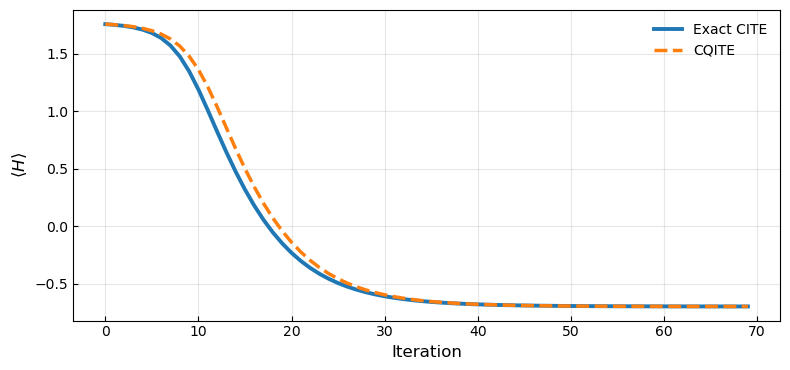

In [253]:
import numpy as np
import matplotlib.pyplot as plt

energies = np.asarray(energies)
energies_exact = np.asarray(energies_exact)

iters = np.arange(len(energies))

fig, ax = plt.subplots(
    figsize=(8, 3.8),
    dpi=100
)

ax.plot(
    iters,
    energies_exact,
    lw=2.8,
    label="Exact CITE"
)

ax.plot(
    iters,
    energies,
    lw=2.5,
    ls="--",
    label="CQITE"
)

ax.set_xlabel("Iteration", fontsize=12)
ax.set_ylabel(r"$\langle H\rangle$", fontsize=12)

ax.grid(True, alpha=0.3)
ax.legend(frameon=False)

ax.tick_params(direction="in")

plt.tight_layout()
fig.savefig("zz_exp.pdf", bbox_inches="tight", transparent=True)
plt.show()

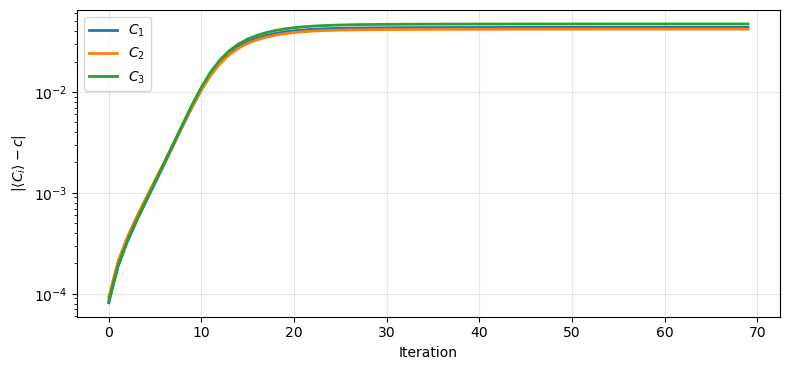

In [255]:
mag = np.asarray(magnetizations)

fig, ax = plt.subplots(
    figsize=(8,3.8)
)

for k in range(mag.shape[1]):
    ax.plot(
        np.abs(mag[:,k]-target),
        lw=2,
        label=rf"$C_{k+1}$"
    )

ax.set_yscale("log")

ax.set_xlabel("Iteration")
ax.set_ylabel(r"$|\langle C_i\rangle-c|$")
ax.grid(alpha=.3)

ax.legend()

plt.tight_layout()

fig.savefig("zz_con.pdf", bbox_inches="tight", transparent=True)